In [ ]:

# 1. IMPORTS AND SETUP


import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

DEVICE = "cpu"
RESULTS_DIR = Path("../results")

In [ ]:

# 2. MODEL DEFINITION
#    Projection Head (same as training)


class ProjectionHead(nn.Module):
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(0.2), nn.Linear(hidden, out_dim),
        )
    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

In [3]:
# ============================================
# 3. LOAD DATA AND MODEL CHECKPOINT
# ============================================

text = np.load(RESULTS_DIR / "text_embeddings_aligned.npy")
audio = np.load(RESULTS_DIR / "audio_embeddings_aligned.npy")
video = np.load(RESULTS_DIR / "video_embeddings_aligned.npy")
ids = np.load(RESULTS_DIR / "id_order.npy", allow_pickle=True)

ckpt = torch.load(RESULTS_DIR / "alignment_model.pt", map_location=DEVICE, weights_only=False)

In [4]:
# ============================================
# 4. STANDARDIZE ALL DATA
#    (Using training stats from checkpoint)
# ============================================

def standardize(mat, mu, sd):
    return ((mat - mu) / sd).astype(np.float32)

text_s = standardize(text, ckpt["t_mu"], ckpt["t_sd"])
audio_s = standardize(audio, ckpt["a_mu"], ckpt["a_sd"])
video_s = standardize(video, ckpt["v_mu"], ckpt["v_sd"])

In [5]:
# ============================================
# 5. LOAD TRAINED PROJECTION HEADS
# ============================================

text_head = ProjectionHead(text.shape[1], 256, 128)
text_head.load_state_dict(ckpt["text_head"])
text_head.eval()

audio_head = ProjectionHead(audio.shape[1], 512, 128)
audio_head.load_state_dict(ckpt["audio_head"])
audio_head.eval()

video_head = ProjectionHead(video.shape[1], 512, 128)
video_head.load_state_dict(ckpt["video_head"])
video_head.eval()

ProjectionHead(
  (net): Sequential(
    (0): Linear(in_features=2304, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=512, out_features=128, bias=True)
  )
)

In [6]:
# ============================================
# 6. GENERATE ALIGNED EMBEDDINGS
#    Project all data to shared space
# ============================================

with torch.no_grad():
    zt = text_head(torch.tensor(text_s)).numpy()
    za = audio_head(torch.tensor(audio_s)).numpy()
    zv = video_head(torch.tensor(video_s)).numpy()

In [7]:
# ============================================
# 7. COMPUTE SIMILARITIES AND MDS
#    MDS = Modality Distance Score
# ============================================

sim_text_audio = (zt * za).sum(axis=1)
sim_text_video = (zt * zv).sum(axis=1)
sim_audio_video = (za * zv).sum(axis=1)
mds = 1 - (sim_text_video + sim_text_audio) / 2

In [8]:
# ============================================
# 8. SAVE RESULTS TO CSV
# ============================================

out = pd.DataFrame({
    "id_hash": ids,
    "sim_text_audio": sim_text_audio,
    "sim_text_video": sim_text_video,
    "sim_audio_video": sim_audio_video,
    "MDS": mds,
})
out.to_csv(RESULTS_DIR / "mds_scores.csv", index=False)

print(out.describe())
print("Saved mds_scores.csv, N =", len(out))

       sim_text_audio  sim_text_video  sim_audio_video          MDS
count     5136.000000     5136.000000      5136.000000  5136.000000
mean         0.746669        0.726117         0.755305     0.263607
std          0.319575        0.289871         0.315234     0.300547
min         -0.371750       -0.410223        -0.366956     0.070675
25%          0.851932        0.828283         0.872983     0.106601
50%          0.899748        0.860258         0.903395     0.119579
75%          0.914741        0.876996         0.917593     0.149832
max          0.957249        0.933124         0.958549     1.264273
Saved mds_scores.csv, N = 5136


In [9]:
# ============================================
# 9. SUMMARY STATISTICS
# ============================================

print("\n" + "="*50)
print("MDS SCORE SUMMARY")
print("="*50)
print(f"Total videos processed: {len(out)}")
print(f"MDS - Mean: {mds.mean():.4f}")
print(f"MDS - Std:  {mds.std():.4f}")
print(f"MDS - Min:  {mds.min():.4f}")
print(f"MDS - Max:  {mds.max():.4f}")
print(f"MDS - Median: {np.median(mds):.4f}")
print("\nMDS Interpretation:")
print("- Lower MDS = Better multi-modal alignment")
print("- MDS close to 0 = High similarity across modalities")
print("- MDS close to 1 = Low similarity (modality mismatch)")


MDS SCORE SUMMARY
Total videos processed: 5136
MDS - Mean: 0.2636
MDS - Std:  0.3005
MDS - Min:  0.0707
MDS - Max:  1.2643
MDS - Median: 0.1196

MDS Interpretation:
- Lower MDS = Better multi-modal alignment
- MDS close to 0 = High similarity across modalities
- MDS close to 1 = Low similarity (modality mismatch)


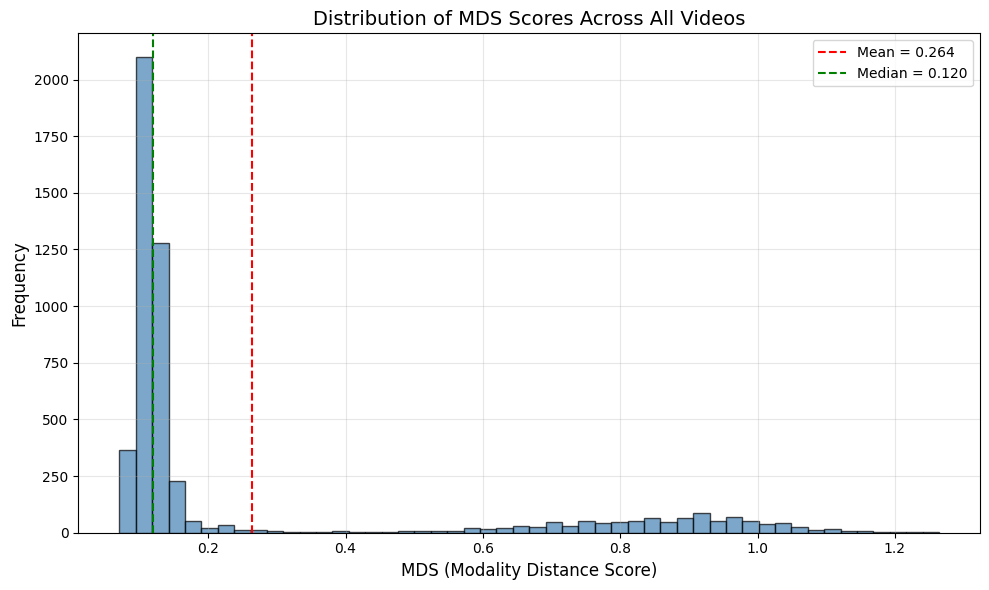

Saved MDS distribution plot to ..\results\mds_distribution.png


In [10]:
# ============================================
# 10. VISUALIZE MDS DISTRIBUTION
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(mds, bins=50, alpha=0.7, color='steelblue', edgecolor='black')
plt.xlabel('MDS (Modality Distance Score)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.title('Distribution of MDS Scores Across All Videos', fontsize=14)
plt.grid(True, alpha=0.3)
plt.axvline(mds.mean(), color='red', linestyle='--', label=f'Mean = {mds.mean():.3f}')
plt.axvline(np.median(mds), color='green', linestyle='--', label=f'Median = {np.median(mds):.3f}')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "mds_distribution.png", dpi=150)
plt.show()
print(f"Saved MDS distribution plot to {RESULTS_DIR / 'mds_distribution.png'}")